# Aviation Safety Text Exploration

**SOURCE: NASA Aviation Safety Reporting System (ASRS)**
(https://asrs.arc.nasa.gov/search/database.html)

**Author:** Kevin Hennelly    
**Date:** November 2026

## Project Overview

This project applies exploratory natural language processing (NLP) techniques to aviation safety reports obtained from NASA's Aviation Safety Reporting System (ASRS).  A small subset of 10 records of safety reports with airspace as a factor were selected at random.  The overall intent is to demonstrate exploratory NLP techniques on aviation safety data rather than focus on root causes broad trends.  

The purpose is to identify recurring terminology, operational themes, and relationships between words in aviation safety narratives. The analysis follows the methods demonstrated in the Dr. Case's `nlp_corpus_explore.py` script, adapted to aviation-related data.

## Analytical Questions

1. What words appear most frequently in aviation safety reports?
2. What operational topics emerge from word frequency analysis?
3. Which aviation related terms commonly appear together?
4. What recurring word pairs can be identified through bigram analysis?
5. How might these patterns help identify potential aviation safety concerns?

## Methods

- Load and prepare NASA ASRS report data from https://asrs.arc.nasa.gov/search/database.html
- Extract and clean narrative text.
- Tokenize text and calculate word frequencies.
- Visualize the most common words.
- Examine word co-occurrence and context.
- Identify frequently occurring bigrams.
- Interpret the findings and potential applications.

## Dataset

The dataset contains 10 imported narrative report records, with a duplicate header row removed during cleaning.

## Expected Outcome

This project demonstrates how basic NLP techniques can reveal patterns in aviation safety narratives before applying more advanced statistical or machine learning methods.


In [3]:
import pandas as pd

# Load NASA ASRS airspace violation reports
df = pd.read_csv("data/ASRS_DBOnline.csv")

# Display the first five records
display(df.head())

,,Time,Time.1,Place,Place.1,Place.2,Place.3,Place.4,Place.5,Place.6,...,Events.4,Events.5,Assessments,Assessments.1,Report 1,Report 1.1,Report 2,Report 2.1,Report 1.2,Unnamed: 125
0,ACN,Date,Local Time Of Day,Locale Reference,State Reference,Relative Position.Angle.Radial,Relative Position.Distance.Nautical Miles,Altitude.AGL.Single Value,Altitude.MSL.Single Value,Latitude / Longitude (UAS),...,When Detected,Result,Contributing Factors / Situations,Primary Problem,Narrative,Callback,Narrative,Callback,Synopsis,NaN
1,1961948,202301,1201-1800,HPN.Airport,NY,340,6.2,NaN,2500,NaN,...,In-flight,Flight Crew Exited Penetrated Airspace,Human Factors; Airspace Structure,Human Factors,On VFR flight from ZZZ to BDR. Navigating arou...,NaN,NaN,NaN,A General Aviation pilot reported briefly ente...,NaN
2,1964198,202301,1201-1800,ZZZ.Airport,US,NaN,NaN,NaN,NaN,NaN,...,In-flight,Flight Crew Became Reoriented,Human Factors,Human Factors,On my return flight from ZZZ to ZZZ1 over [fre...,NaN,NaN,NaN,Pilot flying PA 24 aircraft reported flying to...,NaN
3,1965693,202301,0601-1200,CHD.Tower,AZ,020,2,NaN,2900,NaN,...,In-flight,Flight Crew Exited Penetrated Airspace; Flight...,Human Factors; Aircraft,Human Factors,This was a training flight. The subject airpla...,NaN,NaN,NaN,A General Aviation pilot reported entering CHD...,NaN
4,1965843,202301,1801-2400,ZLC.ARTCC,UT,NaN,NaN,NaN,8600,NaN,...,NaN,Air Traffic Control Issued New Clearance; Flig...,Procedure,Procedure,Aircraft X departed ZZZ; asked for IFR clearan...,NaN,NaN,NaN,ZLC Controller reported failure to issue corre...,NaN


In [4]:
# Find columns containing NASA ASRS report text
text_columns = [
    col
    for col in df.columns
    if "narrative" in col.lower()
    or "synopsis" in col.lower()
    or "report" in col.lower()
]

# Preview the first 150 characters from each text column
for col in text_columns:
    if df[col].notna().any():
        sample = str(df[col].dropna().iloc[0])[:150]
        print(f"{col}: {sample}\n")
    else:
        print(f"{col}: Empty\n")

# Display total number of rows
print(f"Total rows: {len(df)}")

Report 1: Narrative

Report 1.1: Callback

Report 2: Narrative

Report 2.1: Callback

Report 1.2: Synopsis

Total rows: 11


In [5]:
# Remove the extra header row
df = df[df["Report 1"] != "Narrative"].copy()

# Combine narrative text from both report fields
df["narrative"] = (
    df["Report 1"].fillna("").astype(str) + " " + df["Report 2"].fillna("").astype(str)
).str.strip()

# Remove reports without narrative text
df = df[df["narrative"] != ""].copy()

# Verify results
print(f"Total reports: {len(df)}")
print("\nFirst narrative preview:")
print(df["narrative"].iloc[0][:500])

Total reports: 10

First narrative preview:
On VFR flight from ZZZ to BDR. Navigating around NY Class B; which was becoming busy so I monitored the en-route frequencies. Approaching HPN; considered seeking Class D transit clearance; but controller was busy and tone of voice stressed. Previous VFR experience with HPN ATCT has been mixed; so I elected to continue on my own circumnavigating the Class D while monitoring the Tower and departures off Runway 34. No issues or conflicts; and no reference to me on the frequency. Nonetheless; I cut 


In [6]:
# Analyze the most common words in aviation safety narratives

from collections import Counter
import re

# Combine all 10 narratives
all_text = " ".join(df["narrative"]).lower()

# Extract words
words = re.findall(r"\b[a-z]+\b", all_text)

# Remove common English words
stop_words = {
    "the",
    "and",
    "was",
    "were",
    "that",
    "with",
    "from",
    "this",
    "have",
    "had",
    "for",
    "but",
    "not",
    "are",
    "they",
    "you",
    "our",
    "into",
    "when",
    "then",
    "there",
    "would",
    "could",
    "about",
    "after",
    "before",
    "their",
    "which",
    "while",
    "been",
    "what",
    "where",
    "them",
    "his",
    "her",
    "its",
    "did",
    "too",
    "out",
    "all",
    "can",
    "one",
    "two",
    "off",
    "who",
    "how",
    "why",
    "she",
    "him",
    "has",
}

filtered_words = [word for word in words if word not in stop_words and len(word) > 2]

# Count the most frequent words
word_counts = Counter(filtered_words)

print("Top 15 most common words:")
for word, count in word_counts.most_common(15):
    print(f"{word}: {count}")

Top 15 most common words:
flight: 17
aircraft: 15
class: 12
pilot: 12
suas: 10
zzz: 8
airspace: 8
during: 7
rvsm: 7
runway: 6
terrain: 6
msl: 6
drone: 6
route: 5
more: 5


In [7]:
# Calculate relative token frequencies as percentages
# Technical modification carried over from Phase 4

total_words = sum(word_counts.values())

print("Top 15 aviation safety terms by relative frequency:")

for word, count in word_counts.most_common(15):
    percentage = (count / total_words) * 100
    print(f"{word}: {count} occurrences ({percentage:.2f}%)")

Top 15 aviation safety terms by relative frequency:
flight: 17 occurrences (2.15%)
aircraft: 15 occurrences (1.89%)
class: 12 occurrences (1.52%)
pilot: 12 occurrences (1.52%)
suas: 10 occurrences (1.26%)
zzz: 8 occurrences (1.01%)
airspace: 8 occurrences (1.01%)
during: 7 occurrences (0.88%)
rvsm: 7 occurrences (0.88%)
runway: 6 occurrences (0.76%)
terrain: 6 occurrences (0.76%)
msl: 6 occurrences (0.76%)
drone: 6 occurrences (0.76%)
route: 5 occurrences (0.63%)
more: 5 occurrences (0.63%)


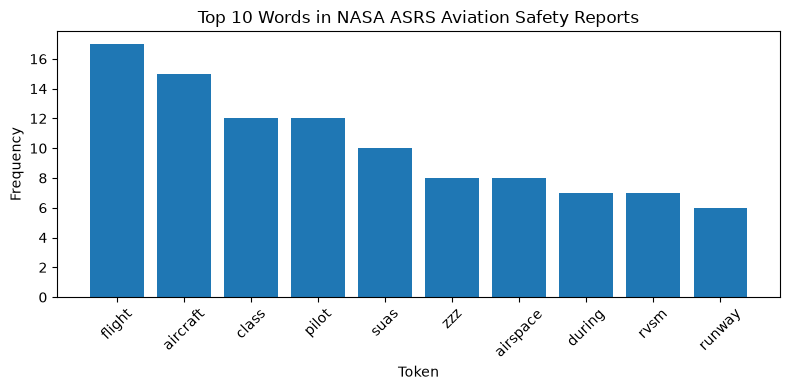

In [8]:
# Visualize Token Frequencies

import matplotlib.pyplot as plt

# Get the 10 most frequent aviation safety words
top_words = word_counts.most_common(10)

words = [word for word, count in top_words]
counts = [count for word, count in top_words]

# Create a figure
plt.figure(figsize=(8, 4))

# Create a bar chart
plt.bar(x=words, height=counts)

# Rotate labels
ax = plt.gca()
ax.tick_params(axis="x", labelrotation=45)

# Add title and labels
plt.title("Top 10 Words in NASA ASRS Aviation Safety Reports")
plt.xlabel("Token")
plt.ylabel("Frequency")

# Adjust layout
plt.tight_layout()

# Display chart
plt.show()

In [9]:
# Analyze Co-occurrence (Context Windows)

from collections import defaultdict

WINDOW_SIZE = 2

co_occurrence_dict = defaultdict(list)

# Examine words appearing near each target word
for i, token in enumerate(filtered_words):
    start = max(0, i - WINDOW_SIZE)
    end = min(len(filtered_words), i + WINDOW_SIZE + 1)

    context = filtered_words[start:end]

    for ctx in context:
        if ctx != token:
            co_occurrence_dict[token].append(ctx)

# Show context for aviation-related terms
for target in ["airspace", "pilot", "aircraft", "runway"]:
    print(f"\nContext for '{target}':")
    print(co_occurrence_dict[target][:10])


Context for 'airspace':
['actually', 'class', 'even', 'weather', 'edge', 'class', 'without', 'clearance', 'chd', 'class']

Context for 'pilot':
['msl', 'both', 'instructor', 'seated', 'smelled', 'gasoline', 'decided', 'return', 'north', 'heading']

Context for 'aircraft':
['familiar', 'airplane', 'departed', 'zzz', 'route', 'cleared', 'wmc', 'airport', 'time', 'thought']

Context for 'runway':
['tower', 'departures', 'issues', 'conflicts', 'inbound', 'both', 'aircraft', 'both', 'aircraft', 'doing']


In [10]:
# Create Bigrams (Local Word Pairs)

# Define a list to store bigrams
bigrams_list = []

# Create pairs of consecutive words
for i in range(len(filtered_words) - 1):
    bigrams_list.append((filtered_words[i], filtered_words[i + 1]))

# Count the frequency of each bigram
bigram_counts = Counter(bigrams_list)

# Show the 10 most common bigrams
print("Top 10 bigrams in NASA ASRS reports:")

for bigram, count in bigram_counts.most_common(10):
    print(f"{bigram[0]} {bigram[1]}: {count}")

Top 10 bigrams in NASA ASRS reports:
class airspace: 5
visual approach: 4
chd class: 3
rules regulations: 3
during flight: 3
exit rvsm: 3
flight zzz: 2
subject airplane: 2
class ceiling: 2
vent tube: 2


## Interpret Results and Identify Patterns

### General Observations

- Flight, aircraft, class, and pilot were among the most frequent words.
- Airspace classifications and flight operations appeared repeatedly.
- Co-occurrence analysis revealed relationships between specific aviation terms.
- Bigram analysis identified recurring word pairs in safety narratives.  However, Given the small data set some like "chd class" (likely referring to CHD tower's airspace) appeared much more than would be found on a broader analysis.  Nevertheless, it shows that an important bigram is to match controlled airspace to it's owner in analyzing safety reports. 
- Potential patterns emerged without using machine learning models.

### Specific Observations

- "Class airspace" appeared 5 times.
- "Visual approach" appeared 4 times.
- "Rules regulations" appeared 3 times.
- The results suggest that airspace classification, flight procedures, and regulatory considerations are recurring topics.
- These techniques could help identify aviation safety trends in larger datasets.

### Conclusion

Exploratory text analysis of NASA ASRS reports demonstrated how token frequencies, co-occurrence, and bigrams can reveal recurring aviation-related topics. Although the dataset is small, the results provide a foundation for more advanced aviation safety analysis.
